# DL 3 — Du MLP au réseau convolutif : classifier des images

Dans [DL 2](DL_2_MLP.ipynb), un MLP classe les fleurs d'Iris à partir de quatre mesures. Que se passe-t-il quand l'entrée est une **image** ? Aplatir les pixels en un long vecteur fait perdre leur organisation spatiale. Ce guide construit un **réseau convolutif** (CNN), d'abord en calculant une convolution à la main avec NumPy, puis avec PyTorch, et le compare à un MLP sur un jeu de données ouvert : **Digits**, des chiffres manuscrits 8×8 fournis avec scikit-learn.

Les données utilisées sont libres et incluses dans scikit-learn : aucun téléchargement ni compte n'est nécessaire.

Chaque section pose une question, la met en pratique et explique comment lire les résultats. Le notebook est autonome : exécuter les cellules **dans l'ordre**, depuis le début. Un GPU n'est pas nécessaire.

| Section | Question |
|---|---|
| 1 | Que contient Digits et comment préparer les images sans fuite ? |
| 2 | Pourquoi aplatir une image fait-il perdre sa structure ? |
| 3 | Que vaut un MLP qui lit les pixels un à un ? |
| 4 | Que calcule une convolution, à la main puis avec PyTorch ? |
| 5 | À quoi sert le pooling ? |
| 6 | Comment construire un CNN, le comparer au MLP et le faire varier ? |
| 7 | Que montrent les filtres et les cartes de caractéristiques ? |
| 8 | Comment juger chaque classe et gérer un jeu déséquilibré ? |
| 9 | Comment évaluer sur des images inédites ? |
| 10 | Que retenir pour un projet réel ? |

### Installer les dépendances

Sur Google Colab ou dans un notebook Jupyter local, exécuter la cellule suivante si nécessaire ; elle installe les bibliothèques dans l'environnement du noyau courant. Une connexion Internet et un Python compatible avec PyTorch peuvent être nécessaires. Si les paquets sont déjà installés, cette étape peut être ignorée. Si demandé, redémarrer le noyau après installation puis reprendre au début.

In [1]:
%pip install -q numpy matplotlib scikit-learn torch


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /home/GTiazara/Documents/venv/notebook/venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

GRAINE = 11
np.random.seed(GRAINE)
torch.manual_seed(GRAINE)

### Reproductibilité et environnement

La graine fixe les tirages utilisés ici. Elle facilite la comparaison, sans garantir exactement les mêmes résultats sur toutes les versions, machines ou tous les périphériques. Les cellules suivantes utilisent le CPU ; un GPU n'est pas nécessaire pour Digits.

## 1. Digits : observer, séparer, normaliser

Digits contient **1797 images** de chiffres manuscrits (0 à 9), numérisées par l'université de Californie (UCI). Chaque image est une grille de **8×8 pixels** dont l'intensité va de 0 (blanc) à 16 (noir). La cible est le chiffre écrit : dix classes. Ces données sont publiques et livrées avec scikit-learn, donc chargées localement, sans téléchargement.

In [3]:
digits = load_digits()
X = digits.images
y = digits.target
noms_chiffres = [str(c) for c in digits.target_names]
print("Images :", X.shape, "| intensités de", X.min(), "à", X.max())
print("Cibles :", y.shape, "| classes :", noms_chiffres)
print("Exemples par chiffre :", np.bincount(y))

Images : (1797, 8, 8) | intensités de 0.0 à 16.0
Cibles : (1797,) | classes : ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Exemples par chiffre : [178 182 177 183 181 182 181 179 174 180]


### Lire le tableau

Chaque image est un tableau $(8, 8)$, et non un vecteur : deux pixels voisins dans la grille décrivent la même région du chiffre. Les dix classes comptent entre 174 et 183 exemples : le jeu est presque équilibré, l'exactitude globale est donc une métrique raisonnable ici. La cellule suivante affiche seize images tirées au hasard.

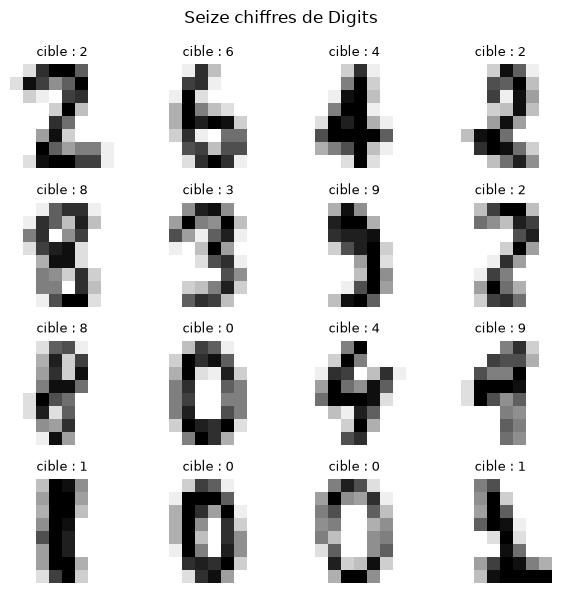

In [4]:
rng = np.random.default_rng(GRAINE)
indices = rng.choice(len(X), size=16, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, i in zip(axes.ravel(), indices):
    ax.imshow(X[i], cmap="gray_r")
    ax.set_title(f"cible : {y[i]}", fontsize=9)
    ax.axis("off")
fig.suptitle("Seize chiffres de Digits")
plt.tight_layout()
plt.show()

### Lire les images

Les chiffres sont centrés et de petite taille, mais leur tracé varie d'un scripteur à l'autre : épaisseur, inclinaison, boucles. Le modèle devra tolérer ces variations. On découpe maintenant en trois ensembles **stratifiés** : entraînement (60 %), validation (20 %) et test (20 %). Comme dans DL 2, la moyenne et l'écart-type servant à normaliser sont calculés **sur l'entraînement seulement**, puis appliqués aux trois ensembles : la validation et le test ne doivent influencer aucun réglage. Pour une image, on utilise une moyenne et un écart-type globaux sur tous les pixels, car tous mesurent la même grandeur physique (une intensité).

In [5]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=GRAINE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=GRAINE, stratify=y_temp
)
moyenne_train = X_train.mean()
ecart_type_train = X_train.std()

def en_tenseur_images(images):
    normalisees = (images - moyenne_train) / ecart_type_train
    return torch.tensor(normalisees, dtype=torch.float32).unsqueeze(1)

X_train_t = en_tenseur_images(X_train)
X_val_t = en_tenseur_images(X_val)
X_test_t = en_tenseur_images(X_test)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)
print("Entraînement :", tuple(X_train_t.shape), "| validation :", tuple(X_val_t.shape), "| test :", tuple(X_test_t.shape))
print(f"Moyenne/écart-type d'entraînement avant normalisation : {moyenne_train:.3f} / {ecart_type_train:.3f}")
print(f"Après normalisation (entraînement) : moyenne = {X_train_t.mean():.3f}, écart-type = {X_train_t.std():.3f}")

Entraînement : (1077, 1, 8, 8) | validation : (360, 1, 8, 8) | test : (360, 1, 8, 8)
Moyenne/écart-type d'entraînement avant normalisation : 4.876 / 6.011
Après normalisation (entraînement) : moyenne = 0.000, écart-type = 1.000


### Lire le découpage et les formes

Les tenseurs d'images ont la forme `(N, 1, 8, 8)` : $N$ images, **1 canal** (niveaux de gris) et une grille 8×8. Une photo couleur aurait 3 canaux. Cette forme à quatre dimensions est celle attendue par les couches de convolution de PyTorch. Après normalisation, l'entraînement a une moyenne proche de 0 et un écart-type proche de 1 ; validation et test, transformés avec les **mêmes** constantes, peuvent s'en écarter légèrement : c'est normal et sans fuite.

## 2. Une image est une grille, pas une simple liste

Un MLP reçoit un vecteur : pour lui donner une image, il faut l'**aplatir** en 64 valeurs. Cette opération oublie quels pixels étaient voisins. Chaque poids de la première couche est alors attaché à **une position fixe** : si le chiffre se décale d'un pixel, d'autres poids reçoivent le tracé et la sortie peut beaucoup changer, alors que le chiffre est le même. L'expérience suivante décale un chiffre d'un pixel (décalage circulaire, par simplicité) et compare les vecteurs aplatis.

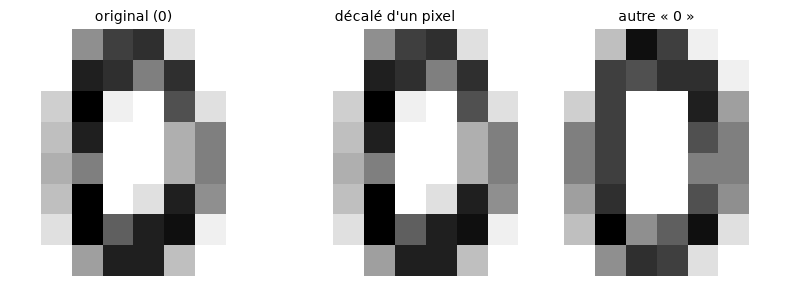

Distance (vecteurs aplatis) original ↔ décalé d'un pixel : 9.35
Distance original ↔ autre exemple du même chiffre        : 2.64


In [6]:
image = X_train_t[0, 0].numpy()
decalee = np.roll(image, 1, axis=1)
meme_classe = np.flatnonzero(y_train == y_train[0])[1]
autre = X_train_t[meme_classe, 0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, (img, titre) in zip(axes, [
    (image, f"original ({y_train[0]})"),
    (decalee, "décalé d'un pixel"),
    (autre, f"autre « {y_train[0]} »"),
]):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(titre, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()
dist_decalage = np.linalg.norm(image.ravel() - decalee.ravel())
dist_autre = np.linalg.norm(image.ravel() - autre.ravel())
print(f"Distance (vecteurs aplatis) original ↔ décalé d'un pixel : {dist_decalage:.2f}")
print(f"Distance original ↔ autre exemple du même chiffre        : {dist_autre:.2f}")

### Lire le décalage

Pour les vecteurs aplatis, l'image décalée d'un seul pixel est ici **plus éloignée** de l'originale qu'un autre exemplaire du même chiffre : la représentation « liste de pixels » ne reflète pas la similarité visuelle. Ce constat vaut pour cette mesure de distance et cet exemple ; il motive une opération qui regarde des **voisinages** de pixels et réutilise les mêmes poids partout : la convolution (section 4). D'abord, mesurons ce que vaut malgré tout un MLP sur les pixels.

## 3. Un MLP de référence sur les pixels

Comme dans DL 2 (section 6), le modèle renvoie des **scores bruts** et la perte est l'**entropie croisée**, adaptée au multiclasse. L'architecture est :

```text
(N, 1, 8, 8) → aplatir (64) → Linear(64, 32) → ReLU → Linear(32, 10) → 10 scores
```

Les 64 entrées sont imposées par la taille des images, les 10 sorties par les dix chiffres ; la couche cachée de 32 neurones est un **choix d'architecture** à comparer sur la validation (voir DL 2). La fonction `entrainer` est générique : elle recevra aussi le CNN de la section 6, avec exactement la même procédure (mini-lots mélangés à chaque époque, SGD avec momentum), pour une comparaison honnête. Ses paramètres optionnels — données d'entraînement et poids de classes — serviront en section 8.

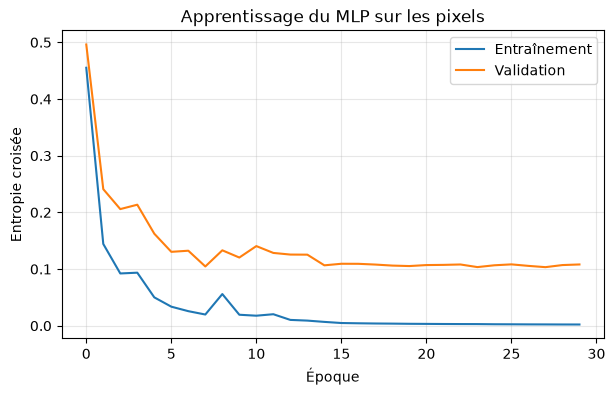

Paramètres du MLP : 2410
Exactitude validation du MLP : 0.981


In [7]:
def creer_mlp(largeur=32):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(64, largeur),
        nn.ReLU(),
        nn.Linear(largeur, 10),
    )

def nombre_parametres(modele):
    return sum(p.numel() for p in modele.parameters())

def exactitude(modele, X_ens, y_ens):
    modele.eval()
    with torch.no_grad():
        return (modele(X_ens).argmax(dim=1) == y_ens).float().mean().item()

def entrainer(fabrique, X_appr=None, y_appr=None, epoques=30, taux=0.1, taille_lot=64,
              poids_classes=None, graine=GRAINE):
    X_appr = X_train_t if X_appr is None else X_appr
    y_appr = y_train_t if y_appr is None else y_appr
    torch.manual_seed(graine)
    generateur = torch.Generator().manual_seed(graine)
    modele = fabrique()
    perte = nn.CrossEntropyLoss(weight=poids_classes)
    optimiseur = optim.SGD(modele.parameters(), lr=taux, momentum=0.9)
    historique = {"train": [], "validation": []}
    for _ in range(epoques):
        modele.train()
        ordre = torch.randperm(len(X_appr), generator=generateur)
        for debut in range(0, len(ordre), taille_lot):
            lot = ordre[debut:debut + taille_lot]
            optimiseur.zero_grad()
            cout = perte(modele(X_appr[lot]), y_appr[lot])
            if not torch.isfinite(cout):
                raise FloatingPointError("Perte non finie : vérifier les données et le taux d'apprentissage.")
            cout.backward()
            optimiseur.step()
        modele.eval()
        with torch.no_grad():
            historique["train"].append(perte(modele(X_appr), y_appr).item())
            historique["validation"].append(perte(modele(X_val_t), y_val_t).item())
    return modele, historique

mlp, historique_mlp = entrainer(creer_mlp)
plt.figure(figsize=(7, 4))
plt.plot(historique_mlp["train"], label="Entraînement")
plt.plot(historique_mlp["validation"], label="Validation")
plt.xlabel("Époque")
plt.ylabel("Entropie croisée")
plt.title("Apprentissage du MLP sur les pixels")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("Paramètres du MLP :", nombre_parametres(mlp))
print(f"Exactitude validation du MLP : {exactitude(mlp, X_val_t, y_val_t):.3f}")

### Lire les courbes

Les deux pertes baissent : le MLP apprend déjà beaucoup, car les chiffres de Digits sont petits, centrés et bien contrastés. C'est la référence à battre. Noter le nombre de paramètres : la première couche en concentre l'essentiel ($64 \times 32 + 32$), et il croît avec la **surface** de l'image. Pour des images 32×32, la même couche demanderait $1024 \times 32 + 32 = 32\,800$ paramètres ; en 224×224, plus d'un million et demi. Il faut une opération dont le coût ne dépende pas de la taille de l'image.

### 3.1 L'outil standard : `Dataset` et `DataLoader`

La boucle de `entrainer` mélange les indices et découpe les mini-lots à la main, pour en montrer la mécanique. PyTorch fournit la même logique prête à l'emploi : un **`Dataset`** sait renvoyer un exemple par indice — ici `TensorDataset` associe chaque image à sa cible ; pour de grands jeux, une classe personnalisée lit chaque exemple depuis le disque à la demande — et un **`DataLoader`** s'occupe du mélange, du découpage en lots et, au besoin, du chargement en parallèle. La cellule suivante vérifie que ce découpage standard correspond au nôtre.

In [8]:
from torch.utils.data import DataLoader, TensorDataset

jeu_entrainement = TensorDataset(X_train_t, y_train_t)
chargeur = DataLoader(jeu_entrainement, batch_size=64, shuffle=True,
                      generator=torch.Generator().manual_seed(GRAINE))
formes = [tuple(images.shape) for images, _ in chargeur]
print("Nombre de mini-lots :", len(formes), "| attendu :", int(np.ceil(len(X_train_t) / 64)))
print("Premier lot :", formes[0], "| dernier lot :", formes[-1])

Nombre de mini-lots : 17 | attendu : 17
Premier lot : (64, 1, 8, 8) | dernier lot : (53, 1, 8, 8)


### Lire le chargeur

Chaque itération renvoie un lot `(images, cibles)` ; le dernier lot est plus petit, sauf si `drop_last=True` l'écarte. La suite du notebook conserve la boucle manuelle, équivalente et plus transparente pour apprendre ; dans un projet réel, préférer `DataLoader`, qui gère aussi les jeux trop grands pour la mémoire.

## 4. La convolution : un petit filtre qui balaie l'image

Une **convolution** fait glisser un petit tableau de poids, le **noyau** (ou filtre), sur l'image. À chaque position, elle multiplie le noyau par le voisinage de pixels correspondant et somme le tout : le résultat forme une **carte de caractéristiques** (*feature map*). Pour un noyau $3\times3$ sur une image $8\times8$, la carte vaut $6\times6$ : le noyau ne déborde pas des bords. Deux idées clés :

- **Partage de poids** : les mêmes 9 poids servent à toutes les positions. Un motif appris à un endroit est détecté partout, et le nombre de paramètres ne dépend pas de la taille de l'image.
- **Localité** : chaque valeur de sortie ne regarde qu'un voisinage de pixels, conformément à la structure de grille.

La cellule suivante applique à la main un noyau fixé — un détecteur de transitions gauche-droite — puis vérifie que `conv2d` de PyTorch donne le même résultat, comme la comparaison NumPy/PyTorch de DL 2.

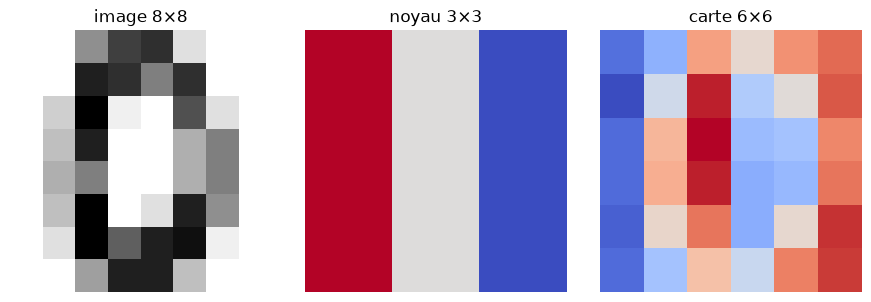

NumPy et PyTorch coïncident : True
Formes : (8, 8) → (6, 6) | paramètres du filtre : 9


In [9]:
noyau = np.array([[1.0, 0.0, -1.0],
                  [1.0, 0.0, -1.0],
                  [1.0, 0.0, -1.0]])
image = X_train_t[0, 0].numpy()
carte_numpy = np.zeros((6, 6))
for i in range(6):
    for j in range(6):
        voisinage = image[i:i + 3, j:j + 3]
        carte_numpy[i, j] = (voisinage * noyau).sum()

carte_torch = F.conv2d(
    torch.tensor(image, dtype=torch.float32).reshape(1, 1, 8, 8),
    torch.tensor(noyau, dtype=torch.float32).reshape(1, 1, 3, 3),
)[0, 0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(image, cmap="gray_r")
axes[0].set_title("image 8×8")
axes[1].imshow(noyau, cmap="coolwarm")
axes[1].set_title("noyau 3×3")
axes[2].imshow(carte_numpy, cmap="coolwarm")
axes[2].set_title("carte 6×6")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("NumPy et PyTorch coïncident :", np.allclose(carte_numpy, carte_torch, atol=1e-5))
print("Formes :", image.shape, "→", carte_numpy.shape, "| paramètres du filtre :", noyau.size)

### Lire la carte de caractéristiques

Les valeurs fortement positives ou négatives de la carte signalent les endroits où l'intensité change entre la gauche et la droite du voisinage : ce noyau répond aux **contours verticaux**. Ici le noyau est fixé à la main pour comprendre le calcul ; dans un CNN, ses 9 poids (plus un biais) sont **appris** par rétropropagation, exactement comme les poids d'une couche `Linear`. Deux réglages usuels complètent l'opération : le **padding** ajoute une bordure de zéros pour conserver la taille (avec `padding=1`, la carte reste 8×8) ; le **stride** fait sauter des positions au filtre pour réduire la carte. Une couche réelle empile plusieurs filtres : `Conv2d(1, 8, 3)` apprend 8 filtres et produit 8 cartes, soit $8 \times (9 + 1) = 80$ paramètres, quelle que soit la taille de l'image.

## 5. Le pooling : résumer chaque petite région

Le **max-pooling** découpe la carte en fenêtres (ici 2×2) et ne garde que le maximum de chacune : la carte 6×6 devient 3×3. Ce résumé n'a **aucun paramètre appris**. Il divise la taille des cartes, donc le calcul des couches suivantes, et rend la sortie moins sensible aux petits décalages : si le contour bouge d'un pixel à l'intérieur de la fenêtre, le maximum ne change pas nécessairement — ce n'est toutefois pas une invariance garantie.

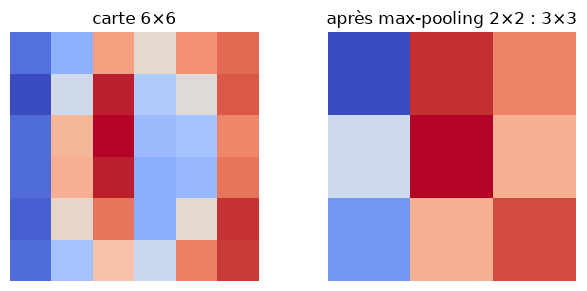

Forme : (6, 6) → (3, 3)


In [10]:
carte_t = torch.tensor(carte_numpy, dtype=torch.float32).reshape(1, 1, 6, 6)
carte_reduite = F.max_pool2d(carte_t, kernel_size=2)[0, 0].numpy()
fig, axes = plt.subplots(1, 2, figsize=(6.5, 3))
axes[0].imshow(carte_numpy, cmap="coolwarm")
axes[0].set_title("carte 6×6")
axes[1].imshow(carte_reduite, cmap="coolwarm")
axes[1].set_title("après max-pooling 2×2 : 3×3")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Forme :", tuple(carte_t.shape[2:]), "→", carte_reduite.shape)

### Lire le pooling

Chaque case de la carte 3×3 résume une fenêtre 2×2 de la carte d'origine : les zones de forte réponse subsistent, la position exacte est partiellement oubliée. L'alternative `AvgPool2d` prend la moyenne au lieu du maximum. En alternant convolutions et pooling, le réseau voit des régions de plus en plus larges de l'image avec des cartes de plus en plus petites : c'est le plan du CNN suivant.

## 6. Le CNN complet : entraîner et comparer au MLP

Le réseau alterne deux blocs convolution + ReLU + pooling, puis une couche entièrement connectée transforme les dernières cartes en 10 scores :

```text
(N, 1, 8, 8) → Conv2d(1, 8, 3, padding=1) → ReLU → MaxPool(2) → (N, 8, 4, 4)
             → Conv2d(8, 16, 3, padding=1) → ReLU → MaxPool(2) → (N, 16, 2, 2)
             → aplatir (64) → Linear(64, 10) → 10 scores
```

Les nombres de filtres (8 puis 16) sont des **hyperparamètres**, comme la largeur de la couche cachée du MLP en DL 2 : à comparer sur la validation, pas des valeurs théoriquement optimales. L'entraînement réutilise `entrainer` à l'identique : mêmes données, même perte, même optimiseur, même graine. Seule l'architecture change. La classe accepte deux options, `normalisation` et `tete`, qui préparent les variantes des sections 6.1 et 6.2 ; par défaut, le réseau est exactement celui du schéma ci-dessus.

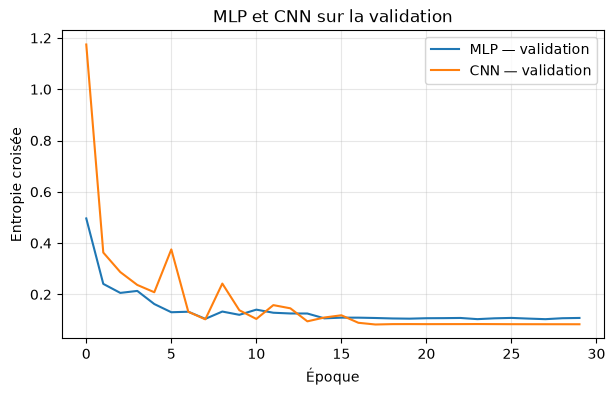

MLP : 2410 paramètres | exactitude validation = 0.981
CNN : 1898 paramètres | exactitude validation = 0.978


In [11]:
class CNN(nn.Module):
    def __init__(self, canaux=(8, 16), normalisation=False, tete="aplatir"):
        super().__init__()
        c1, c2 = canaux

        def bloc(entree, sortie):
            couches = [nn.Conv2d(entree, sortie, kernel_size=3, padding=1)]
            if normalisation:
                couches.append(nn.BatchNorm2d(sortie))
            couches += [nn.ReLU(), nn.MaxPool2d(2)]
            return couches

        self.extracteur = nn.Sequential(*bloc(1, c1), *bloc(c1, c2))
        if tete == "moyenne":
            self.classifieur = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c2, 10))
        else:
            self.classifieur = nn.Sequential(nn.Flatten(), nn.Linear(c2 * 2 * 2, 10))

    def forward(self, x):
        return self.classifieur(self.extracteur(x))

cnn, historique_cnn = entrainer(CNN)
plt.figure(figsize=(7, 4))
plt.plot(historique_mlp["validation"], label="MLP — validation")
plt.plot(historique_cnn["validation"], label="CNN — validation")
plt.xlabel("Époque")
plt.ylabel("Entropie croisée")
plt.title("MLP et CNN sur la validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"MLP : {nombre_parametres(mlp)} paramètres | exactitude validation = {exactitude(mlp, X_val_t, y_val_t):.3f}")
print(f"CNN : {nombre_parametres(cnn)} paramètres | exactitude validation = {exactitude(cnn, X_val_t, y_val_t):.3f}")

### Lire la comparaison

Le CNN atteint une exactitude de validation comparable à celle du MLP — ici légèrement inférieure — avec **moins de paramètres**, car ses poids sont partagés sur toute l'image. Sur Digits, petit et bien centré, l'écart reste faible et peut pencher d'un côté ou de l'autre selon la graine : l'avantage des convolutions grandit avec la taille des images et la variabilité des positions. Rappels de DL 2 : une comparaison sur une seule graine et une seule validation n'est pas une preuve générale ; changer l'architecture change aussi l'initialisation. Ne pas utiliser le test pour départager les modèles.

### 6.1 Stabiliser l'entraînement : la normalisation par lots

La **normalisation par lots** (*batch normalization*) recentre et réduit chaque canal sur le mini-lot courant, puis applique un facteur d'échelle et un décalage **appris** — deux paramètres par canal. Placée entre la convolution et ReLU, elle stabilise la distribution des activations et permet souvent des entraînements plus rapides, ou des taux d'apprentissage plus grands. Point important : son comportement diffère entre `train()` (statistiques du lot courant) et `eval()` (moyennes glissantes mémorisées pendant l'entraînement) — une raison de plus de basculer correctement les modes, comme le fait `entrainer`. L'option `normalisation=True` insère `nn.BatchNorm2d` après chaque convolution.

In [12]:
cnn_bn, _ = entrainer(lambda: CNN(normalisation=True))
print(f"CNN sans BatchNorm : {nombre_parametres(cnn)} paramètres | validation = {exactitude(cnn, X_val_t, y_val_t):.3f}")
print(f"CNN avec BatchNorm : {nombre_parametres(cnn_bn)} paramètres | validation = {exactitude(cnn_bn, X_val_t, y_val_t):.3f}")

CNN sans BatchNorm : 1898 paramètres | validation = 0.978
CNN avec BatchNorm : 1946 paramètres | validation = 0.989


### Lire la normalisation par lots

Sur un petit réseau et des images déjà normalisées, le gain peut être minime : la BatchNorm montre surtout son intérêt sur des réseaux profonds ou des entraînements instables. Le surcoût en paramètres appris reste modeste (deux par canal, plus des statistiques non apprises). Comme pour la largeur, un seul essai sur une seule graine ne permet pas de conclure en général.

### 6.2 Variante : moyenne spatiale avant la couche finale

Le CNN de référence **aplatit** les cartes 2×2 : la couche finale attache encore un poids à chaque position. Une alternative classique — utilisée notamment par ResNet — consiste à **moyenner chaque carte sur tout l'espace** (*global average pooling*) : les 16 cartes deviennent un vecteur de 16 valeurs répondant à « ce motif est-il présent, en moyenne ? », indépendamment de sa position. La tête devient `Linear(16, 10)` : moins de paramètres, et la même tête accepterait des images plus grandes sans modification.

In [13]:
cnn_moyenne, _ = entrainer(lambda: CNN(tete="moyenne"))
print(f"Tête aplatie : {nombre_parametres(cnn)} paramètres | validation = {exactitude(cnn, X_val_t, y_val_t):.3f}")
print(f"Tête moyenne : {nombre_parametres(cnn_moyenne)} paramètres | validation = {exactitude(cnn_moyenne, X_val_t, y_val_t):.3f}")

Tête aplatie : 1898 paramètres | validation = 0.978
Tête moyenne : 1418 paramètres | validation = 0.981


### Lire la moyenne spatiale

Moyenner jette la position exacte des motifs : sur des chiffres 8×8 où un même trait en haut ou en bas distingue deux classes, cela peut coûter un peu d'exactitude ; sur de grandes images où l'objet peut se trouver n'importe où, c'est souvent un avantage. Le choix de la tête est un hyperparamètre de plus, à comparer sur la validation.

### 6.3 Optimiseur Adam et taux d'apprentissage à paliers

Jusqu'ici, l'optimiseur est SGD avec momentum et un taux fixe, comme dans DL 1 et DL 2. Deux outils standard complètent la panoplie :

- **Adam** adapte la taille du pas pour chaque paramètre à partir de moyennes des gradients ; c'est un bon réglage par défaut en classification, avec des taux plus petits (autour de $10^{-3}$).
- Un **programmateur** (*scheduler*) comme `MultiStepLR` multiplie le taux par un facteur à des époques choisies, les paliers : grands pas au début, pas plus fins à la fin. `programmateur.step()` s'appelle une fois par époque, après les mises à jour.

In [14]:
def entrainer_adam(fabrique, epoques=30, taux=1e-3, paliers=(20, 25), facteur=0.5,
                   taille_lot=64, graine=GRAINE):
    torch.manual_seed(graine)
    generateur = torch.Generator().manual_seed(graine)
    modele = fabrique()
    perte = nn.CrossEntropyLoss()
    optimiseur = optim.Adam(modele.parameters(), lr=taux)
    programmateur = optim.lr_scheduler.MultiStepLR(optimiseur, milestones=list(paliers), gamma=facteur)
    taux_suivis = []
    for _ in range(epoques):
        modele.train()
        ordre = torch.randperm(len(X_train_t), generator=generateur)
        for debut in range(0, len(ordre), taille_lot):
            lot = ordre[debut:debut + taille_lot]
            optimiseur.zero_grad()
            perte(modele(X_train_t[lot]), y_train_t[lot]).backward()
            optimiseur.step()
        taux_suivis.append(optimiseur.param_groups[0]["lr"])
        programmateur.step()
    return modele, taux_suivis

cnn_adam, taux_suivis = entrainer_adam(CNN)
print("Taux observés :", sorted(set(taux_suivis), reverse=True), "| paliers aux époques 20 et 25")
print(f"CNN avec Adam + paliers : validation = {exactitude(cnn_adam, X_val_t, y_val_t):.3f}")

Taux observés : [0.001, 0.0005, 0.00025] | paliers aux époques 20 et 25
CNN avec Adam + paliers : validation = 0.936


### Lire l'optimiseur et les paliers

Les trois valeurs du taux correspondent aux paliers demandés : $10^{-3}$, puis la moitié, puis le quart. Comparer des optimiseurs exige les mêmes précautions que comparer des architectures : mêmes données, même graine, mêmes époques, et la validation seulement. Adam converge souvent plus vite au début ; le meilleur réglage final dépend des données et du budget d'entraînement.

## 7. Regarder ce que le réseau a appris

Deux objets se visualisent directement : les **filtres** de la première couche (leurs 9 poids, appris) et les **cartes de caractéristiques** produites sur une image donnée. La lecture reste qualitative : avec des filtres 3×3 sur des images 8×8, tous n'ont pas une interprétation évidente, et les cartes dépendent de l'image choisie.

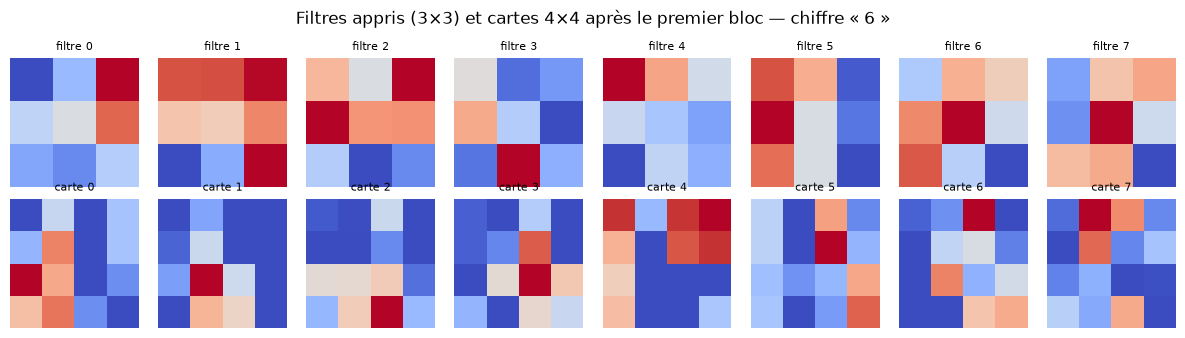

In [15]:
image_val = X_val_t[:1]
with torch.no_grad():
    poids_filtres = cnn.extracteur[0].weight[:, 0].numpy()
    cartes_bloc1 = cnn.extracteur[2](cnn.extracteur[1](cnn.extracteur[0](image_val)))[0].numpy()

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for k in range(8):
    axes[0, k].imshow(poids_filtres[k], cmap="coolwarm")
    axes[0, k].set_title(f"filtre {k}", fontsize=8)
    axes[1, k].imshow(cartes_bloc1[k], cmap="coolwarm")
    axes[1, k].set_title(f"carte {k}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(f"Filtres appris (3×3) et cartes 4×4 après le premier bloc — chiffre « {y_val[0]} »")
plt.tight_layout()
plt.show()

### Lire les filtres et les cartes

Chaque filtre appris joue le rôle du détecteur de contours de la section 4, mais ses poids viennent de la rétropropagation. Chaque carte 4×4 indique où son filtre répond sur ce chiffre : certains réagissent aux traits verticaux, d'autres aux horizontaux ou aux extrémités. Les cartes du second bloc combinent ces réponses en motifs plus abstraits : ce sont les **caractéristiques cachées** du CNN, l'équivalent spatial des neurones cachés de DL 2.

## 8. Des métriques par classe et les classes déséquilibrées

L'exactitude globale peut masquer une classe entière : avec 95 % d'exemples « sains », un modèle qui prédit toujours « sain » atteint 95 % d'exactitude en ratant tous les autres cas. Les métriques **par classe** se lisent dans la matrice de confusion $M$, où $M_{ij}$ compte les exemples de la classe $i$ prédits $j$ :

$$\mathrm{IoU}_i = \frac{M_{ii}}{M_{ii} + \sum_{j \neq i}\left(M_{ij} + M_{ji}\right)}$$

L'**IoU** (*intersection sur union*) de la classe $i$ rapporte ses vrais positifs à l'ensemble des exemples réels ou prédits de cette classe : elle pénalise à la fois les oublis (faux négatifs) et les fausses alertes (faux positifs). Sa moyenne sur les classes, le **mIoU**, donne le même poids à chaque classe, contrairement à l'exactitude globale. Calculons-les pour le CNN de référence, sur la validation.

In [16]:
def iou_par_classe(matrice):
    vrais_positifs = np.diag(matrice).astype(float)
    union = matrice.sum(axis=0) + matrice.sum(axis=1) - vrais_positifs
    return vrais_positifs / np.maximum(union, 1)

def bilan_par_classe(modele, X_ens, y_ens):
    modele.eval()
    with torch.no_grad():
        predictions = modele(X_ens).argmax(dim=1).numpy()
    matrice = confusion_matrix(y_ens.numpy(), predictions, labels=np.arange(10))
    return (predictions == y_ens.numpy()).mean(), iou_par_classe(matrice)

oa_val, ious_val = bilan_par_classe(cnn, X_val_t, y_val_t)
print(f"Validation : exactitude globale = {oa_val:.3f} | mIoU = {ious_val.mean():.3f}")
print('\n'.join(f"chiffre {c} : IoU = {iou:.3f}" for c, iou in enumerate(ious_val)))

Validation : exactitude globale = 0.978 | mIoU = 0.957
chiffre 0 : IoU = 1.000
chiffre 1 : IoU = 0.921
chiffre 2 : IoU = 1.000
chiffre 3 : IoU = 0.947
chiffre 4 : IoU = 0.972
chiffre 5 : IoU = 0.946
chiffre 6 : IoU = 0.973
chiffre 7 : IoU = 0.972
chiffre 8 : IoU = 0.944
chiffre 9 : IoU = 0.897


### Lire les IoU

Sur Digits, presque équilibré, exactitude globale et mIoU racontent la même histoire, mais le détail des IoU montre déjà quels chiffres résistent le plus. Pour voir les deux métriques diverger, fabriquons un déséquilibre.

### 8.1 Un entraînement déséquilibré et la perte pondérée

On rejoue l'entraînement en ne gardant que **trois exemplaires du chiffre « 8 »** — un chiffre déjà difficile — dans l'ensemble d'entraînement ; la validation et le test ne changent pas. Deux modèles sont comparés, à réglages identiques : la perte habituelle, puis une **perte pondérée** `CrossEntropyLoss(weight=...)` qui amplifie le coût des erreurs sur la classe rare. Les poids se choisissent typiquement à l'inverse des fréquences observées dans l'entraînement ; ici, le poids du « 8 » avoisine 32. Attention : de si grands poids amplifient certains gradients, et avec le taux habituel de 0,1 l'entraînement pondéré devient instable (voir DL 2 sur les taux trop grands). Les deux essais utilisent donc un taux réduit à 0,02.

In [17]:
indices_huit = np.flatnonzero(y_train == 8)
indices_gardes = np.concatenate([np.flatnonzero(y_train != 8), indices_huit[:3]])
X_desequilibre = X_train_t[indices_gardes]
y_desequilibre = y_train_t[indices_gardes]
comptes = np.bincount(y_desequilibre.numpy(), minlength=10)
print("Exemples par chiffre dans l'entraînement déséquilibré :", comptes)

poids = torch.tensor(len(y_desequilibre) / (10.0 * comptes), dtype=torch.float32)
print("Poids de classes :", np.round(poids.numpy(), 2))
cnn_sans_poids, _ = entrainer(CNN, X_desequilibre, y_desequilibre, taux=0.02)
cnn_avec_poids, _ = entrainer(CNN, X_desequilibre, y_desequilibre, taux=0.02, poids_classes=poids)
for nom, modele_essai in [("sans poids", cnn_sans_poids), ("avec poids", cnn_avec_poids)]:
    oa, ious = bilan_par_classe(modele_essai, X_val_t, y_val_t)
    print(f"{nom} : exactitude = {oa:.3f} | mIoU = {ious.mean():.3f} | IoU du 8 = {ious[8]:.3f}")

Exemples par chiffre dans l'entraînement déséquilibré : [106 109 107 109 109 109 109 107   3 108]
Poids de classes : [ 0.92  0.9   0.91  0.9   0.9   0.9   0.9   0.91 32.53  0.9 ]


sans poids : exactitude = 0.914 | mIoU = 0.856 | IoU du 8 = 0.333
avec poids : exactitude = 0.936 | mIoU = 0.888 | IoU du 8 = 0.514


### Lire la pondération

Sans pondération, l'exactitude globale reste élevée alors que l'IoU du « 8 » s'effondre : c'est exactement l'écart entre exactitude et mIoU annoncé plus haut — la métrique globale masque la classe sacrifiée. La pondération relève nettement l'IoU de la classe rare, et ici le mIoU avec elle. Trois réserves : les poids sont un hyperparamètre de plus (trop forts, ils déstabilisent l'entraînement ou sacrifient les autres classes) ; la pondération ne remplace pas des données supplémentaires pour la classe rare ; et une seule graine ne permet pas de conclure en général.

## 9. Évaluer sur des images inédites

On choisit le CNN comme modèle de référence et on l'évalue **une seule fois** sur le test, resté à l'écart de tout réglage. Une prédiction est correcte si le score maximal désigne le bon chiffre ; la matrice de confusion compte les chiffres réels en lignes et les chiffres prédits en colonnes.

Exactitude sur 360 images de test : 0.972


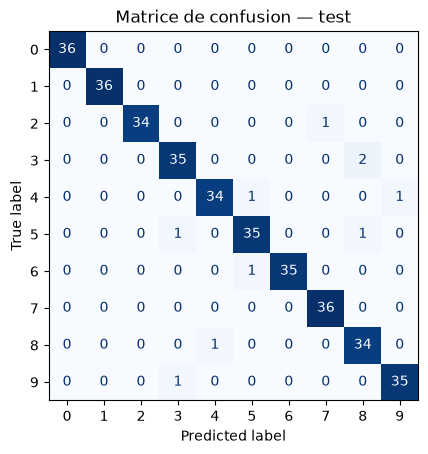

mIoU sur le test : 0.947 | IoU minimale : chiffre 8 (0.895)


In [18]:
cnn.eval()
with torch.no_grad():
    predictions_test = cnn(X_test_t).argmax(dim=1).numpy()
score_test = accuracy_score(y_test, predictions_test)
print(f"Exactitude sur {len(y_test)} images de test : {score_test:.3f}")
matrice = confusion_matrix(y_test, predictions_test, labels=np.arange(10))
ConfusionMatrixDisplay(matrice, display_labels=noms_chiffres).plot(cmap="Blues", colorbar=False)
plt.title("Matrice de confusion — test")
plt.show()
ious_test = iou_par_classe(matrice)
print(f"mIoU sur le test : {ious_test.mean():.3f} | IoU minimale : chiffre {ious_test.argmin()} ({ious_test.min():.3f})")

### Lire l'évaluation

La diagonale indique les bonnes prédictions ; les cases hors diagonale montrent quels chiffres se confondent (souvent des formes proches comme 3/8 ou 4/9). Le mIoU, proche de l'exactitude sur ce jeu équilibré, signale avec son IoU minimale le chiffre le plus fragile. Le test doit rester réservé à l'évaluation finale : s'en servir pour choisir le modèle le rendrait dépendant. Avec environ 360 images de test, quelques erreurs de plus ou de moins déplacent sensiblement le score : un bon résultat ici ne prouve pas que le CNN surpasserait le MLP sur d'autres données.

## 10. Bilan — ce qu'un ingénieur IA retient du CNN

| Question | Réponse |
|---|---|
| Pourquoi pas un MLP sur les pixels ? | Aplatir oublie les voisinages ; les poids sont attachés à des positions fixes et leur nombre croît avec la surface de l'image. |
| Que calcule une convolution ? | Un petit noyau appris glisse sur l'image et produit une carte de caractéristiques ; mêmes poids partout (partage), voisinages seulement (localité). |
| À quoi sert le pooling ? | Résumer chaque petite région sans paramètre appris : cartes plus petites, sensibilité réduite aux petits décalages. |
| Comment se structure un CNN ? | Des blocs convolution + activation + pooling qui élargissent le champ vu, puis une tête (aplatissement ou moyenne spatiale) vers les scores. |
| À quoi sert la BatchNorm ? | Recentrer chaque canal sur le mini-lot stabilise l'entraînement ; son comportement diffère entre `train()` et `eval()`. |
| Exactitude ou mIoU ? | L'exactitude globale peut masquer les classes rares ; l'IoU par classe et le mIoU donnent le même poids à chaque classe. |
| Et si les classes sont déséquilibrées ? | Pondérer la perte (`CrossEntropyLoss(weight=...)`), typiquement à l'inverse des fréquences, et surveiller les métriques par classe. |
| Quels outils standard ? | `Dataset`/`DataLoader` pour les lots, Adam comme optimiseur par défaut raisonnable, un scheduler pour les paliers de taux. |
| Comment choisir filtres et canaux ? | Comme la largeur d'un MLP (DL 2) : des hyperparamètres à comparer sur la validation, en gardant le test pour la fin. |
| Que surveiller ? | Les formes des tenseurs `(N, canaux, hauteur, largeur)`, les pertes train/validation, le nombre de paramètres et les confusions. |

### Pour aller plus loin

1. Ajouter un `nn.Dropout` avant la couche finale du CNN et comparer plusieurs taux sur la validation (voir DL 2, section 6.3).
2. Faire varier le nombre de filtres `canaux=(4, 8)` puis `(16, 32)` : le gain justifie-t-il les paramètres supplémentaires ?
3. Ajouter un troisième bloc convolution + pooling : avec des cartes 2×2 en entrée, que devient leur taille ? Adapter l'architecture pour que cela reste possible.
4. Réduire l'entraînement à 25 % des images (sous-échantillonnage stratifié) et comparer la chute du MLP et celle du CNN.
5. Rejouer la section 8.1 avec d'autres poids de classes, ou un autre chiffre raréfié : la conclusion change-t-elle ?
6. Entraîner une forêt aléatoire de scikit-learn sur les vecteurs aplatis comme référence sans réseau de neurones.
7. Reprendre cette fiche avec MNIST (28×28, via `torchvision`) : l'écart MLP/CNN se creuse-t-il ?

### Sources

- [Optical Recognition of Handwritten Digits — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits) et [load_digits — documentation scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html) — données ouvertes et chargement.
- [Conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) et [MaxPool2d](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) — documentation PyTorch des couches utilisées.
- LeCun, Bottou, Bengio, Haffner (1998), [*Gradient-Based Learning Applied to Document Recognition*](https://ieeexplore.ieee.org/document/726791) — le réseau LeNet, ancêtre de l'architecture de cette fiche.
- [CS231n — Convolutional Neural Networks](https://cs231n.github.io/convolutional-networks/) — notes de cours de Stanford sur les CNN.
- [3Blue1Brown — réseaux de neurones](https://www.3blue1brown.com/topics/neural-networks) — intuitions animées.

Digits est un petit jeu de données pédagogique : des images 8×8 centrées ne représentent pas la difficulté des images réelles, et une seule séparation ne suffit pas pour conclure à la qualité d'un modèle en production. Les résultats peuvent varier selon les versions de bibliothèques et les environnements.